# Comprehensive Flagging Tutorial

_The previous tutorial (tutorial 2) discussed bitmasks and how to manipulate flag bitmasks we developed for M3. Here we will cover what each flag means for data quality. We will also generate a flag file for an existing L1B observation._

In [1]:
import numpy as np                # for scientific computing, good for working with large arrays  
import pandas as pd               # for data analysis, has easy to work with data frames 
import matplotlib.pyplot as plt   # for plotting
from matplotlib.colors import ListedColormap
from astropy.io import fits       # for reading / writing / manipulating FITS files 

import sys
sys.path.append('../') 

# FLAG DEFINITIONS 
NO_FLAG = 0
L2_DEPRECATED = 1 # bit 0, bands flagged by the mission in L2 as deprecated
NAN = 2           # bit 1, pixels set to NaN for being negative at L0 level
BDE = 4           # bit 2, pixels spectrally interpolated bc of the BDE
BAD_COL = 8       # bit 3, pixels part of a column offset from its neighbors
# FLAGS FOR FLICKER FLAGGING
NO_FLICKER = 16   # bit 4, bad-group column, no flicker on this line
FLICKER_BUMP = 32 # bit 5, flickers brighter than neighbors
FLICKER_DROP = 64 # bit 6, flickers darker than neighbors
# FLAGS REMAINING:  128 / bit 7

## Flag Meanings 

As a refresher, the flag values are as follows: 

| Flag          | Value | Binary      | Bit position | Meaning                                              |
|---------------|-------|-------------|--------------|------------------------------------------------------|
| NO_FLAG       | 0     | `00000000`  |             | No flag set                                          |
| L2_DEPRECATED | 1     | `00000001`  | bit 0        | Band flagged by the mission in L2 as deprecated      |
| NAN           | 2     | `00000010`  | bit 1        | Pixel set to NaN for being negative at L0 level      |
| BDE           | 4     | `00000100`  | bit 2        | Column spectrally interpolated because of the BDE     |
| BAD_COL       | 8     | `00001000`  | bit 3        | Column offset from its neighbors  |
| NO_FLICKER    | 16    | `00010000`  | bit 4        | Bad-group column, no flicker on this line            |
| FLICKER_BUMP  | 32    | `00100000`  | bit 5        | Flickers brighter than neighbors                     |
| FLICKER_DROP  | 64    | `01000000`  | bit 6        | Flickers darker than neighbors                       |

### Flag 1: L2 Deprecated 
Between L1B (radiance) and L2 (reflectance), the mission deprecated a selection of bands. These bands were processed to L1B but all of their values were set to -999 in L2. All pixels in these deprecated bands are flagged with `flag 1`. 

* For target mode these bands were: [0, 1, 2, 3, 4, 5, 6, 7, 255]

* For global mode these bands were: [0, 1] 

_Because global mode averages target mode bands together, the target-mode bands deprecated in L2 are averaged into global band 85, which is not flagged._

### Flag 2: Negative L0 Values / NAN

L0 raw observational data (DN) was stored as a 12-bit unsigned integer on the spacecraft but saved as a 16-bit signed integer in the PDS. 
This means the maximum value observed in L0 data is 4095. Such high values are typically only observed in target mode, which was not as downsampled as global mode, where the largest values are around 3000. 

There appears to have been a rollover effect, where, when values surpassed 4095, they became 0 in target mode and 0, -1, or -2 in global mode. The dark signal background of normal observational data not experiencing this rollover effect is typically at least 300 DN. Therefore we set 0 and negative values in the L0 observational data to NAN in the pipeline and flag it with `flag 2`. 

This rollover effect was covered for the dark signal observations with flag 1.5 in the mission-produced BDE maps. 

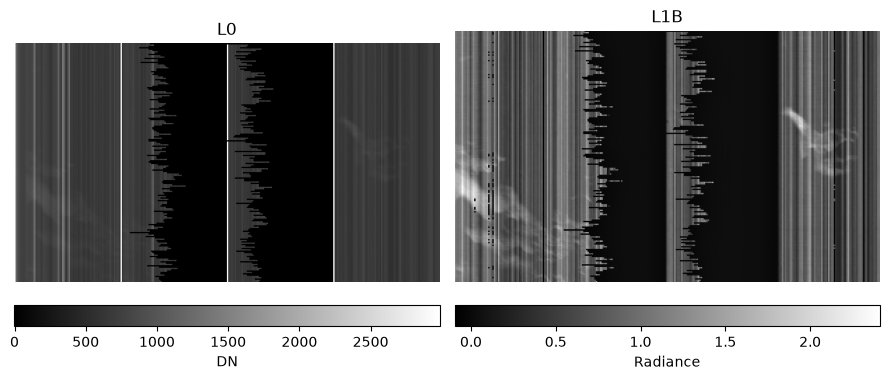

In [2]:
# load l0 and l1b data 
path_to_negative_l0 = "./tutorial_data/l0_m3g20081118t222604_b83.fits"   # for file size purposes I saved only one band of this obs
with fits.open(path_to_negative_l0) as hdul:
    l0 = hdul[0].data
    
path_to_negative_l1b = "./tutorial_data/l1b_m3g20081118t222604_b82.fits" # band index for l1b global mode is offset from l0 by one
with fits.open(path_to_negative_l1b) as hdul:
    l1b = hdul[0].data

# choose section of the band to view 
l0_section = l0[1000:1180, :]
l1b_section = l1b[1000:1180, :]

# show both images with colorbars 
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 6))
im1 = ax1.imshow(l0_section, cmap="gray")
ax1.set_title("L0")
fig.colorbar(im1, ax=ax1, orientation="horizontal", pad=0.04, label="DN")
ax1.axis('off')
im2 = ax2.imshow(l1b_section, cmap="gray")
ax2.set_title("L1B")
fig.colorbar(im2, ax=ax2, orientation="horizontal", pad=0.04, label="Radiance")
ax2.axis('off')
plt.tight_layout()
plt.show()

Above is an example global-mode L0 observation (left) with negative pixels at band 83. These negative values were converted to radiance in the L1B product on the right. The pattern of these rollovers usually looks like a sideways histogram, as above. 

We think these rollover values are usually a result of high detector temperatures above ~165 K. 

### Flag 4: Bad Detector Elements (BDE) 

The original mission files have flag backplanes they call bad detector element maps (BDE) that are generated from dark signal observations. These files have the same orientation and number of bands & samples as the L0 data, but not the L1B data. They are provided in the USGS PDS as files ending in '_bde.fits'. These BDE maps are in detector POV, where the x-axis is samples (cross-track) and the y-axis is bands / channels

__As part of calibration, flagged pixels in the BDE maps were linearly spectrally interpolated. This means values at the interpolated pixels are not true observational data.__

Here is an example BDE map from the mission. 

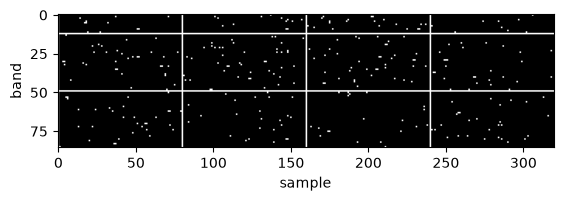

In [3]:
bde_id = 'm3g20090420t201515'
path_to_bde = f"./tutorial_data/{bde_id}_bde.fits"
with fits.open(path_to_bde) as hdul: 
    mission_bde = hdul[0].data
# the BDE maps have different values for different flags, but anything over 0 was flagged and spectrally interpolated
plt.imshow(mission_bde>0, cmap='grey')
plt.xlabel('sample')
plt.ylabel('band')
plt.show()

The mission-derived BDE maps have the same number of bands and samples / columns as the L0 data. To flag L1B data as spectrally interpolated by the mission, we use the orientation information from the label files to reverse the lines and/or samples, if indicated. 
We also trim the bands and samples to match the L1B data. 

`Flag 4` is applied for all lines of a pixel flagged in the BDE map. This means every `flag 4` pixel in a band was interpolated from the closest unflagged bands and is not a real measurement.

#### BDE Maps of Warm Observations 
The number of pixels flagged in a BDE map is highly correlated with observation temperature. Warmer observations are more heavily flagged because their dark signal observations have higher overall values and more variability. Very hot observations (>170 K), never processed to L1B by the mission, have almost entirely flagged BDE maps. 

Below is a BDE map derived from a warm dark signal observation (167 K). This BDE map was used in processing observation m3g20081225t133906. 

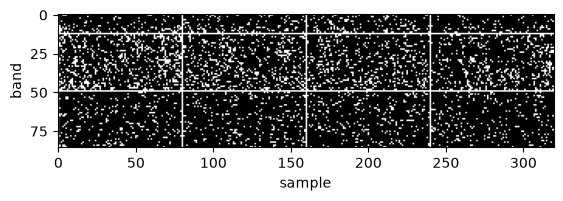

In [4]:
bde_id = 'm3g20081225t130812'
path_to_bde = f"./tutorial_data/{bde_id}_bde.fits"
with fits.open(path_to_bde) as hdul: 
    mission_bde = hdul[0].data
# the BDE maps have different values for different flags, but anything over 0 was flagged and spectrally interpolated
plt.imshow(mission_bde>0, cmap='grey')
plt.xlabel('sample')
plt.ylabel('band')
plt.show()

#### Remaking the BDE Maps 

The specific thresholds and method for making the BDE maps were not disclosed by the mission. However, we know they used the dark signal observation standard deviation and mean values. 

You can recreate their BDE maps using our function below, if you so desire. They are very close to the same, although not always exactly. **For flagging pre-existing L1B data, we recommend you download the BDE map produced by the mission from the PDS.**

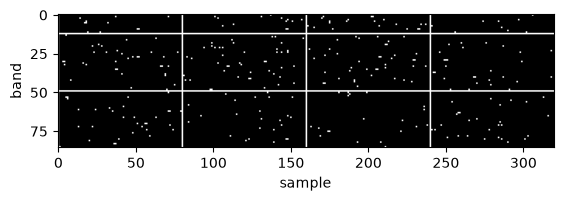

In [5]:
from m3_pipeline_tools.flagging.primary_flagging import call_build_bde_mask

# observation ID is the date, time, and mode designation unique to every observation in the M3 corpus 
# in every file name in the PDS this is the part that goes before _l0.fits, _l2_rfl.fits etc 
obs_id = "m3g20090420t191718" 

# local root, where data is stored 
local_root = './tutorial_data'

# call build mask 
bde = call_build_bde_mask(obs_id=obs_id, local_root= local_root)

# the BDE maps have different values for different flags, but anything over 0 was flagged and spectrally interpolated
plt.imshow(bde>0, cmap='grey')
plt.xlabel('sample')
plt.ylabel('band')
plt.show()

### Flag 8: Bad Column Flag 

For a variety of reasons, "bad" columns of data persist in L1B products: 
* Poor flat field, especially when the flat field was derived from another observation.
* Dark signal observation not temporally close
* Dark signal observation and the 'real' observation differ significantly in temperature.
* A flashing, bright, or very dark pixel is not flagged in the BDE map, either because it is just below the threshold for flagging or
  because it didn't flash during the relatively short dark signal observation used to make the BDE map. 

`Flag 8` is for identifying the most egregious columns in each band of an observation. Columns that are flagged with this flag are flagged for _all lines_ of the observation because the column is shown to have a persistent offset from its neighboring columns for most of the observation. In the L0 to L1B pipeline, this flag is only set after flat fielding. 

An example `flag 8` column in band 23 of an L1B file is shown below. 

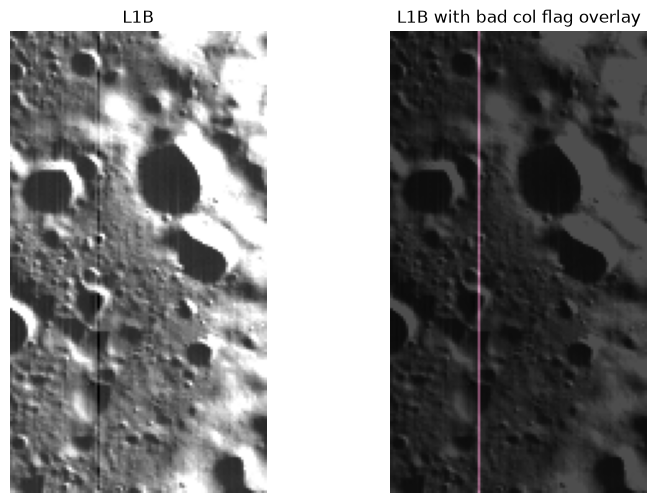

In [6]:
# load l1b data and flag map derived from that l1b file 
path_to_l1b = "./tutorial_data/m3g20090420t191718_l1b_rdn.fits"
with fits.open(path_to_l1b) as hdul: 
    rdn = hdul[0].data
path_to_flag = "./tutorial_data/m3g20090420t191718_flag.fits"
with fits.open(path_to_flag) as hdul: 
    flag = hdul[0].data

# area / band of interest 
band = 23 # 0-indexed 
line_start = 370 
line_stop = 550
sample_start = 100
sample_stop = 200

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 6))
l1b_section = rdn[band, line_start:line_stop, sample_start:sample_stop]
vmin, vmax = np.nanpercentile(l1b_section, [0, 90])
l1b_clipped = np.clip(l1b_section, vmin, vmax)                            # clip l1b data to show bad col more clearly 
flag_section = flag[band, line_start:line_stop, sample_start:sample_stop]
im1 = ax1.imshow(l1b_clipped, cmap="gray")
ax1.set_title("L1B")
ax1.axis('off')
im1 = ax2.imshow(l1b_clipped, cmap="gray")
f1 = ax2.imshow((flag_section & BAD_COL) != 0, cmap='okabe_ito', alpha=.7) # select only the BAD_COL flag of the bitmask 
ax2.set_title("L1B with bad col flag overlay")
ax2.axis('off')
plt.show()

There are other visibly 'offset' columns in the clipped version of the L1B data shown above. The bad column flag is not meant to flag 
_every_ column in M3 data with an offset from its neighbors / a streaky appearance. For warm observations, trying to flag every slightly bad column would result in entire bands being flagged. 

#### Bad Column ID Method
The method for flagging these bad columns is laid out in the `secondary_flagging` module. The secondary flagging process is run on one band at a time. Briefly: 
1. Each column / sample in the band is differenced with its neighboring column to the left and to the right. Left and right differences are kept separate.
2. Pixels in each difference image are flagged using the difference image statistics: $|Diff_{xy}| > |\operatorname{median}(Diff)| + k \cdot \sigma(Diff)$, where k is a standard deviation multiplier (`std_multiplier`) currently set to 0.5.
3. We compute the flagged fraction of each column. Entire columns are then flagged when their fraction of flagged pixels exceeds a minimum % flagged. That minimum is the larger value of the following: either 0.6 (`flag_col_ratio`) or the 96th percentile of flagged column fractions. This effectively caps the number of flagged columns per band at 4% of columns. 

**Notes**:
* If you want _more_ bad columns flagged per band, reducing the `std_multiplier`, the `flag_col_ratio` or the 96th percentile cutoff would be good places to start.
* Because the threshold for flagging is defined per band, a slightly offset column flagged in a brighter band with high SNR would likely not be flagged in a dimmer, noisier band. 
* This flagging method will not identify several adjacent columns that are offset from the rest of the image. That is likely a flat field issue. Noisy and persistently dim or bright pixels, which the mission called 'bad detector elements', infrequently occur in more than two adjacent columns/samples.
* Target mode frequently has two adjacent bad pixels in a band. This algorithm is designed to flag pairs of bad adjacent columns, but sometimes one is missed due to thresholds being a little too high, etc. You may want to dilate the bad column flag by a column for target mode observations. Bad pixels are less frequently in pairs for global mode (global mode samples/columns are downsampled by 2 from target mode). 
* Using neighboring column differences can pick up bright edges, like crater rims, as 'bad pixels'. This is normally fine, because crater
rims _usually_ are not perfectly straight nor span the length of an observation. If an observation is unusually short and has lots of  features oriented along the image columns, though, this flag may be erroneously set.

### Flags 16, 32, 64: Flicker Flags 

__What is flickering?__
We observed two groups of columns / samples in the detector that periodically 'flicker' darker or brighter than the rest of the background periodically during an observation. These groups are evenly spaced and always the same columns. They also appear to flash at the same time and with the same magnitude across all bands. We think this is an electronic background effect. 

The previous two flags, `flag 4` (BDE maps) and `flag 8` (bad columns), are applied to all lines of a column. What we refer to as the 'flicker flags' vary across the lines of an observation. `Flag 32` and `flag 64` are set only for lines where flickering is detected. 

#### Flickering in Dark Signal Observations
Below is the standard deviation of the dark signal observation (m3g20090420t201515) used in processing observation m3g20090420t191718. 
There is an obvious set of evenly spaced columns with locally high standard deviation across all bands of m3g20090420t201515. 

The indices of the bright columns in the dark std image below are consistent across observations. The two groups we identified for global mode are highlighted in the second image below. 

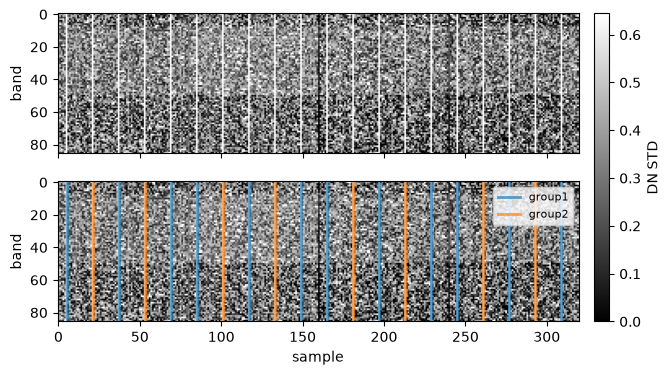

In [7]:
dark_id = 'm3g20090420t201515'
path_to_dark = f"./tutorial_data/{dark_id}_l0.fits"
with fits.open(path_to_dark) as hdul: 
    dark = hdul[0].data
dark_std = np.std(dark[:, 1:-1, :], axis=1)
vmin, vmax = np.nanpercentile(dark_std, [0, 90])
dark_std_clipped = np.clip(dark_std, vmin, vmax)   # clip std image to show columns more clearly 

# 0-indexed, L0 shape flicker groups identified by hand 
flicker_groups = {
    'group1': np.array([309, 277, 245, 229, 197, 165, 149, 117, 85, 69, 37, 5]),
    'group2': np.array([293, 261, 213, 181, 133, 101, 53, 21]),
}  
group_colors = {'group1': 'tab:blue', 'group2': 'tab:orange'}
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 4), sharex=True)
im = ax1.imshow(dark_std_clipped, cmap='grey')
ax1.set_ylabel('band')
ax2.imshow(dark_std_clipped, cmap='grey')
for name, cols in flicker_groups.items():
    for i, col in enumerate(cols):
        ax2.axvline(col, color=group_colors[name], lw=2, alpha=0.7,
                    label=name if i == 0 else None)
ax2.set_xlabel('sample')
ax2.set_ylabel('band')
ax2.legend(loc='upper right', fontsize=8, framealpha=0.8)
fig.colorbar(im, ax=[ax1, ax2], orientation='vertical', pad=0.02, label='DN STD')
plt.show()

#### Flickering in Observations 

Flickering during observations is most obvious in cold observations, where the noise introduced by warm detector conditions doesn't override the electronic background signal. Below is an example target mode observation showing the evenly spaced flicker columns turning on and off. This observation is quite large, so only band 9 is stored in the tutorial data folder.

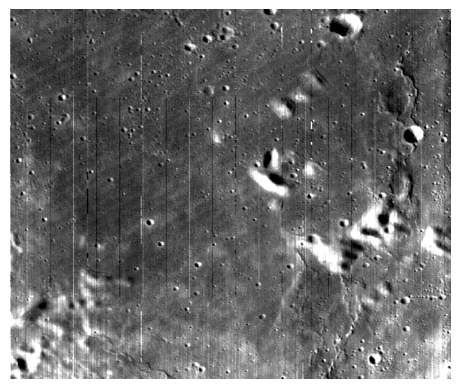

In [8]:
path_to_l1b = f"./tutorial_data/m3t20090416t030323_l1b_rdn_b9.fits"
with fits.open(path_to_l1b) as hdul: 
    l1b = hdul[0].data  
    
line_start = 1890
line_stop = 2400

plt.imshow(l1b[line_start:line_stop,:], cmap='grey', vmin=5, vmax=12) # clip to show flicker lines clearly 
plt.axis('off')
plt.show()

#### Flicker Flags 
There are three flags in the flicker flag group:
* `Flag 16`: Columns known to flicker but with no apparent offset at a given line. 
* `Flag 32`: Columns known to flicker that are brighter than their neighboring columns for a given line.
* `Flag 64`: Columns known to flicker that are darker than their neighboring columns for a given line.

Below is an example of a set of flagged flickering columns from the same target mode observation as above. 

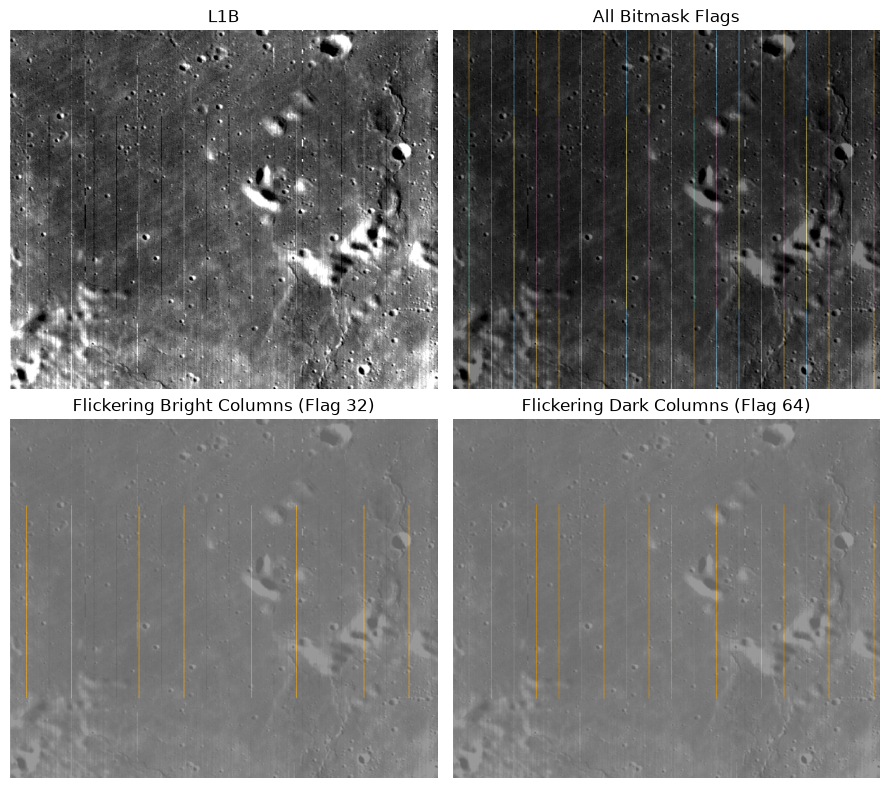

In [9]:
path_to_flag = f"./tutorial_data/m3t20090416t030323_flag_b9.fits"
with fits.open(path_to_flag) as hdul: 
    flag = hdul[0].data
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(9, 8))
two_colors = ListedColormap(['grey', 'orange'])
for ax in (ax1, ax2, ax3, ax4):
    ax.imshow(l1b[line_start:line_stop,:], cmap='grey', vmin=5, vmax=12)
    ax.axis('off')
ax1.set_title("L1B") 
ax2.set_title("All Bitmask Flags") 
allflags = ax2.imshow(flag[line_start:line_stop,:], cmap='okabe_ito', alpha=.5)
ax3.set_title("Flickering Bright Columns (Flag 32)")
bump = ax3.imshow((flag[line_start:line_stop,:] & FLICKER_BUMP) != 0, cmap=two_colors, alpha=.8) # select pixels where flicker is bright
ax4.set_title("Flickering Dark Columns (Flag 64)")
drop = ax4.imshow((flag[line_start:line_stop,:] & FLICKER_DROP) != 0, cmap=two_colors, alpha=.8) # select pixels where flicker is dark
plt.tight_layout()
plt.show()

__Why set a flag for known flickering columns when there is no flickering detected?__ 

We set `Flag 16` (shown in the upper right image above) because flicker detection is not infallible. Especially in warm observations or sections of an observation with a wide variety of terrain across-track, flickering groups may be missed. 

Additionally, at the L1B level, flickering groups have already been modified by other pipeline steps, like flat fielding. Flat fielding 
the flickering columns isn't really the correct calibration behavior because flicker is 1) additive to the background signal and 2) temporally variable.  

Below is the flat field for the observation shown above, m3t20090416t030323. At lower bands (towards the top), some of the known flickering columns are faintly visible in the flat field pattern. The flickering column groups are highlighted on the right. 

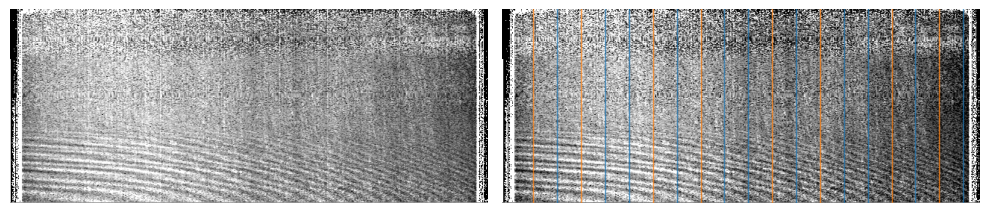

In [10]:
path_to_flat = f"./tutorial_data/m3t20090416t030323_ff.fits"
with fits.open(path_to_flat) as hdul: 
    flat = hdul[0].data
    
# 0-indexed, L0 shape flicker groups identified by hand for Target mode 
flicker_groups = {'group1': np.array([73, 137, 169, 233, 297, 329, 393, 457, 489, 553, 617]),
                 'group2': np.array([41, 105, 201, 265, 361, 425, 521, 585]),} 

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6))
im = ax1.imshow(flat, cmap='grey', vmin=.7, vmax=1.2)
ax2.imshow(flat, cmap='grey', vmin=.8, vmax=1.2)
for name, cols in flicker_groups.items():
    for i, col in enumerate(cols):
        ax2.axvline(col, color=group_colors[name], lw=1, alpha=0.7,
                    label=name if i == 0 else None)
ax1.axis('off')
ax2.axis('off')
plt.tight_layout()
plt.show()

#### Flicker Flagging Method 

Currently, flickering is identified in a set of low bands of an observation. The flickering flags in those low bands are then set for all
bands. We do this because:
* It is faster.
* From observation, flickering behaves the same across all bands in L0 data.
* Flickering is more difficult to detect at high bands, where the SNR for real observational data is better.

The broad steps used in the module `flicker_flagging` for detecting flickering lines are as follows: 
_Detection is run once for each group of flickering columns (currently there are 2)._
1. Create a list of "normal" columns offset by 5 pixels to the right from the list of flickering columns. 
Steps A-C are run for both the normal and flickering columns:
    1. Take each column's difference with the median of its 4 neighboring columns (2 either side). 
    1. For each line, take the median of the column difference values.
    1. Look for change line-to-line by subtracting the median of a window (currently 25 lines) before and after each line.
2. Identify peaks in the output of step C for the flickering columns with a minimum peak height equal to $6.0 \cdot (MAD \cdot 1.4826)$ of the "normal" column step C result. These are potentially the start or stop of a flicker on or off.
3. Use the peaks ID'd in step 2 to get segments of flickering lines. The median of the differences of all lines within a segment is the magnitude of that section of flickering. The sign of the magnitude indicates if the flicker is bright (`flag 32`) or dark (`flag 64`). 
4. To be flagged in the flag map as `flag 32` or `flag 64`, the magnitude found in step 3 must be at least $4.0 \cdot (MAD \cdot 1.4826)$ of the per-line "normal" column differences. 

#### Offset for Flickering

__So if flickering is an additive offset, can we fix it instead of flagging it?__ 
Hypothetically, yes. But not for pre-existing L1B data. We cannot fix the L1B data using an offset map derived from one band because each band has been transformed independently of each other from the original L0 data. Also, as you saw above, the flickering columns are sometimes modified by the flat field. 

For L0 data, in the current 'new' version of the pipeline, we do add back the offset found for segments in step 3. This assumes that the flickering column magnitude and sign is equivalent across all bands for a segment. The function `make_offset_map` in the module `flicker_flagging` generates the offset map from the flickering segments identified by `check_flicker_group`. 

## Flagging Pre-Existing L1B Data

We can flag an already existing L1B observation with the BDE map, L0 data, and L1B data. This outputs only a flag backplane. 

###  Required Data 
To make a flag backplane from an existing L1B product you will need: 
* the L1B observation data

You should have but aren't required to have: 
* the L0 observation data
   - if this isn't present we can't flag pixels that are negative in the L0 data 
* the BDE map ('bde_id')
   - if this isn't present we can't flag what was spectrally interpolated by the mission
 
If the L0 data or BDE map isn't present, the flagging function will print a warning but allow you to output a flag map. 

These files should all be stored in the local root you give the function. They should all be the PDS4 FITS file versions of the data, stored in the USGS PDS. 

#### How to know what files are required? 

* The L0 and L1B data have the same observation ID at the beginning of their filenames.
* The BDE maps are stored in the `document/calibration_data/bad_detector_elements` folder of the USGS PDS. The correct BDE ID for an observation is stored in `src/m3_pipeline_tools/cal_data/l1b_processing_info.csv`.

For convenience, you can also look up the BDE ID by doing the following: 

In [11]:
from m3_pipeline_tools.reference import check_observation   # import function for checking observation metadata 

# check_observation returns a tuple where the first two entries are warnings & errors. Here we only care about the metadata dictionary.
_, _, metadata = check_observation(obs_id)  # pass obs ID string

print(f"The bde ID is {metadata['bde_id']}, in the PDS the filename will be {metadata['bde_id']}_bde.fits")

The bde ID is m3g20090420t201515, in the PDS the filename will be m3g20090420t201515_bde.fits


### Generating the L1B-based Flag Map 

To generate an L1B-based flag map, use the function `make_mission_l1b_flag_backplane`. It returns an array with the same shape as the L1B file. 

In [12]:
# import function for making flag map for L1B 
from m3_pipeline_tools.flagging.make_flag_backplanes import make_mission_l1b_flag_backplane

flag = make_mission_l1b_flag_backplane(
    obs_id = obs_id.lower(),
    local_root = local_root,    # where our required files are stored 
    verbose=True,
)
    
fits.writeto(f'{local_root}/{obs_id}_flag.fits', flag, overwrite=True)
del flag

#### L1B vs L2 

Recall that L2 data has a set of channels that are marked deprecated and all set to -999. When the L1B-based flag map is overlain on an L2 observation, it will still show all of the flags for quality issues visible in L1B. However, all of the reflectance values will be -999, so there aren't _really_ any bad columns or flickering columns etc. 